## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)).alias("spread_return"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid", "spread_return"]).last()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,40,00), pl.time(15,49,59)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("signed_dollar_imbalance") / pl.col("ADV"))
            .clip(-1,1)
        ).alias("signed_mean_imb_ratio"),
        # (
        #     (pl.col("signed_dollar_imbalance") / pl.col("dollar_imbalance").mean().over(pl.col("date")))
        # ).alias("signed_cross_imb_ratio"),
        (
            ((pl.col("signed_dollar_imbalance").rank().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))) 
             / (pl.col("signed_dollar_imbalance").rank().max().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_imb"),
        (
            pl.col("signed_dollar_imbalance").sum().over("date") / pl.col("paired_dollars").sum().over("date")
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        # (pl.col("signed_mean_imb_ratio") * pl.col("recent_return")).alias("imb_x_recent_return"),
        # (pl.col("norm_rank_imb") * pl.col("recent_return")).alias("rank_x_recent_return"),
        (pl.col("norm_rank_imb") * pl.col("net_signed_imb")).alias("rank_x_net_imb")
    )
)

# The dataframe we will be working with
data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,signed_mean_imb_ratio,norm_rank_imb,net_signed_imb,return_to_close,rank_x_net_imb
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAPL""","""A""",2559352,198.78,198.79,0.000201,203.23,2.2199e9,0.0,5.4590e7,5.0875e8,-1,-5.4590e7,-0.024591,-0.871795,-0.133971,0.022335,0.116795
2025-06-11,"""ABNB""","""B""",125932,137.75,137.68,0.000436,140.24,1.3647e8,0.001091,7.7486e6,1.7347133e7,1,7.7486e6,0.056779,0.641026,-0.133971,0.018594,-0.085879
2025-06-11,"""ADBE""","""B""",127948,412.78,412.61,0.000291,415.2,2.5565e8,-0.001271,3.1611e6,5.2814e7,1,3.1611e6,0.012365,0.435897,-0.133971,0.006277,-0.058398
2025-06-11,"""ADI""","""B""",387104,231.77,231.605,0.000475,234.09,1.4346e8,0.000648,9.6931e6,8.9719e7,1,9.6931e6,0.067567,0.74359,-0.133971,0.010729,-0.099619
2025-06-11,"""ADP""","""B""",109179,311.72,311.575,0.000417,314.375,8.8407e7,-0.001266,4.7553e6,3.4033e7,1,4.7553e6,0.053789,0.512821,-0.133971,0.008987,-0.068703
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""TXN""","""A""",937022,282.53,282.645,0.000743,285.82,4.8747e8,-0.003877,3.1504e7,2.6474e8,-1,-3.1504e7,-0.064627,-0.670886,-0.011046,0.011233,0.00741
2026-06-10,"""UAL""","""B""",459492,102.84,102.855,0.000292,105.74,1.0664e8,-0.000097,2.9506e6,4.7254e7,1,2.9506e6,0.027668,0.392405,-0.011046,0.028049,-0.004334
2026-06-10,"""VOO""","""N""",0,0.0,668.235,0.000015,674.28,4.2164e8,-0.001032,0.0,0.0,0,0.0,0.0,0.075949,-0.011046,0.009046,-0.000839


### Shapley Values

In [4]:
import sklearn
import statsmodels.api as sm

features = ["signed_mean_imb_ratio", "norm_rank_imb", "rank_x_net_imb"]

scaler = sklearn.preprocessing.StandardScaler()

X = scaler.fit_transform(data[features].to_pandas())
y = data["return_to_close"].to_pandas()

model = sklearn.linear_model.Ridge(alpha=1e-1)
model.fit(X,y)

print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")

Model coefficients:

signed_mean_imb_ratio = -0.0001900938
norm_rank_imb = 0.0009004314
rank_x_net_imb = -0.0005278477


In [5]:
import shap

# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
# shap.partial_dependence_plot(
#     "norm_rank_imb",
#     model.predict,
#     X,
#     model_expected_value=True,
#     feature_expected_value=True,
#     ice=False,
#     shap_values=shap_values[sample_ind : sample_ind + 1, :],
# )

Background dataset has 20288 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=20288 when initializing the masker.


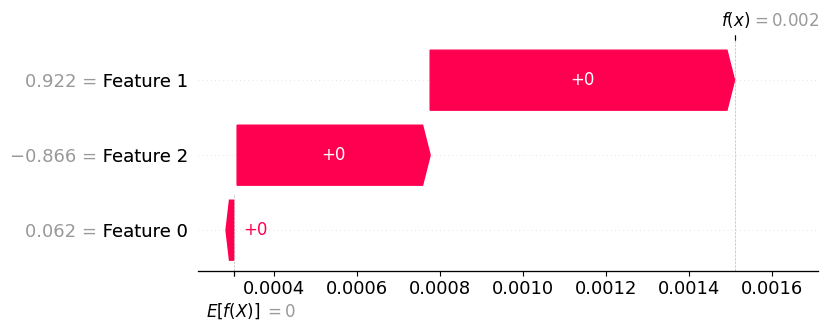

In [6]:
shap.plots.waterfall(shap_values[sample_ind])

### IC Study

In [33]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from scipy.stats import spearmanr

# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
features = ["signed_mean_imb_ratio", "norm_rank_imb", "rank_x_net_imb"]

tscv = TimeSeriesSplit(n_splits=49, max_train_size=30, test_size=5)  # rolling ~120-day train window
scaler = StandardScaler()

fold_ics = []
fold_metrics = []
for i, (train_d, test_d) in enumerate(tscv.split(dates)):
    train_dates = [dates[j] for j in train_d]
    test_dates  = [dates[j] for j in test_d]

    train = data.filter(pl.col("date").is_in(train_dates))
    test  = data.filter(pl.col("date").is_in(test_dates))

    X_train_scale = scaler.fit_transform(train[features].to_numpy())
    y_train = train["return_to_close"].to_numpy()
    X_test_scale = scaler.transform(test[features].to_numpy())
    y_test = test["return_to_close"].to_numpy()

    model = Ridge(alpha=1e-1)
    model.fit(X_train_scale, y_train)

    # Forecast on test, then daily cross-sectional rank IC (Spearman), averaged.
    pred = (
        test
        .with_columns(pl.Series("yhat", model.predict(X_test_scale)))
    )
    daily_ic = (
        pred.group_by("date")
        .agg(
            pl.map_groups(
                exprs=["yhat", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic")
        )
        .drop_nulls()
    )
    mean_ic = daily_ic["ic"].mean()
    fold_ics.append(mean_ic)
    mse, mae, rmse = mean_squared_error(y_test, pred['yhat'].to_numpy()), mean_absolute_error(y_test, pred['yhat'].to_numpy()), root_mean_squared_error(y_test, pred['yhat'].to_numpy())
    fold_metrics.append(
        (mse, mae, rmse)
    )
    # print(f"fold {i}: train {train_dates[0]}..{train_dates[-1]} "
    #       f"({len(train_dates)}d) | test {test_dates[0]}..{test_dates[-1]} "
    #       f"({len(test_dates)}d) | mean daily IC = {mean_ic:+.4f}"
    #       f"| MSE = {mse:+.4f}"
    #       f"| MAE = {mae:+.4f}"
    #       f"| RMSE = {rmse:+.4f}")
fold_ics = np.array(fold_ics)
print(f"\nMean IC across folds: {np.mean(fold_ics):+.4f}  "
      f"(IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f}, Ann: {np.mean(np.sqrt(255) * fold_ics) / np.std(fold_ics):+.2f})"
      f"\nStd IC across folds: {np.std(fold_ics):+.4f}  "
      f"\nMean MSE across folds: {np.mean([mse for (mse, mae, rmse) in fold_metrics]):+.4f}  "
      f"\nMean MAE across folds: {np.mean([mae for (mse, mae, rmse) in fold_metrics]):+.4f}  "
      f"\nMean RMSE across folds: {np.mean([rmse for (mse, mae, rmse) in fold_metrics]):+.4f}  ")


Mean IC across folds: +0.0245  (IR = +0.36, Ann: +5.72)
Std IC across folds: +0.0685  
Mean MSE across folds: +0.0005  
Mean MAE across folds: +0.0154  
Mean RMSE across folds: +0.0219  


In [25]:
# Same IC study, but manual walk-forward with NON-OVERLAPPING train sets.
# TimeSeriesSplit above uses a rolling 90d window stepped 1 day at a time, so
# consecutive folds share ~89/90 of their training dates. Here we instead cut the
# date axis into contiguous, disjoint TRAIN_SIZE-day blocks; fold k trains on block k
# and tests on block k+1. No date appears in two different train sets.
# Splits are still on unique DATES so each day's cross-section stays whole.

TRAIN_SIZE = 30   # length of each disjoint train block (days)
TEST_SIZE  = 30   # length of the test block that immediately follows it (days)
STEP       = TRAIN_SIZE  # step by TRAIN_SIZE -> train windows never overlap

dates = data["date"].unique().sort().to_list()
features = ["signed_mean_imb_ratio", "norm_rank_imb", "rank_x_net_imb"]
scaler = StandardScaler()

fold_ics = []
fold_metrics = []
start = 0
fold = 0
while start + TRAIN_SIZE + 1 <= len(dates):
    train_dates = dates[start : start + TRAIN_SIZE]
    test_dates  = dates[start + TRAIN_SIZE : start + TRAIN_SIZE + TEST_SIZE]
    if not test_dates:
        break

    train = data.filter(pl.col("date").is_in(train_dates))
    test  = data.filter(pl.col("date").is_in(test_dates))

    X_train_scale = scaler.fit_transform(train[features].to_numpy())
    y_train = train["return_to_close"].to_numpy()
    X_test_scale = scaler.transform(test[features].to_numpy())
    y_test = test["return_to_close"].to_numpy()

    model = Ridge(alpha=1e-1)
    model.fit(X_train_scale, y_train)

    # Forecast on test, then daily cross-sectional rank IC (Spearman), averaged.
    pred = test.with_columns(pl.Series("yhat", model.predict(X_test_scale)))
    daily_ic = (
        pred.group_by("date")
        .agg(
            pl.map_groups(
                exprs=["yhat", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic")
        )
        .drop_nulls()
    )
    mean_ic = daily_ic["ic"].mean()
    fold_ics.append(mean_ic)
    mse  = mean_squared_error(y_test, pred["yhat"].to_numpy())
    mae  = mean_absolute_error(y_test, pred["yhat"].to_numpy())
    rmse = root_mean_squared_error(y_test, pred["yhat"].to_numpy())
    fold_metrics.append((mse, mae, rmse))
    print(f"fold {fold}: train {train_dates[0]}..{train_dates[-1]} "
          f"({len(train_dates)}d) | test {test_dates[0]}..{test_dates[-1]} "
          f"({len(test_dates)}d) | mean daily IC = {mean_ic:+.4f}"
          f" | MSE = {mse:+.4f} | MAE = {mae:+.4f} | RMSE = {rmse:+.4f}")

    start += STEP
    fold += 1

fold_ics = np.array(fold_ics)
print(f"\n{len(fold_ics)} non-overlapping folds"
      f"\nMean IC across folds: {np.mean(fold_ics):+.4f}  "
      f"(IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f}, Ann: {np.mean(np.sqrt(255) * fold_ics) / np.std(fold_ics):+.2f})"
      f"\nStd IC across folds: {np.std(fold_ics):+.4f}  "
      f"\nMean MSE across folds: {np.mean([mse for (mse, mae, rmse) in fold_metrics]):+.4f}  "
      f"\nMean MAE across folds: {np.mean([mae for (mse, mae, rmse) in fold_metrics]):+.4f}  "
      f"\nMean RMSE across folds: {np.mean([rmse for (mse, mae, rmse) in fold_metrics]):+.4f}  ")


fold 0: train 2025-06-11..2025-07-25 (30d) | test 2025-07-28..2025-09-08 (30d) | mean daily IC = +0.0077 | MSE = +0.0003 | MAE = +0.0125 | RMSE = +0.0177
fold 1: train 2025-07-28..2025-09-08 (30d) | test 2025-09-09..2025-10-20 (30d) | mean daily IC = +0.0317 | MSE = +0.0005 | MAE = +0.0138 | RMSE = +0.0214
fold 2: train 2025-09-09..2025-10-20 (30d) | test 2025-10-21..2025-12-03 (30d) | mean daily IC = +0.0470 | MSE = +0.0006 | MAE = +0.0167 | RMSE = +0.0252
fold 3: train 2025-10-21..2025-12-03 (30d) | test 2025-12-04..2026-01-20 (30d) | mean daily IC = +0.0326 | MSE = +0.0004 | MAE = +0.0139 | RMSE = +0.0198
fold 4: train 2025-12-04..2026-01-20 (30d) | test 2026-01-21..2026-03-04 (30d) | mean daily IC = +0.0632 | MSE = +0.0007 | MAE = +0.0186 | RMSE = +0.0263
fold 5: train 2026-01-21..2026-03-04 (30d) | test 2026-03-05..2026-04-16 (30d) | mean daily IC = +0.0292 | MSE = +0.0006 | MAE = +0.0169 | RMSE = +0.0242
fold 6: train 2026-03-05..2026-04-16 (30d) | test 2026-04-17..2026-05-29 (30

### Search for Regime Detecting Variables
Regressing the daily IC from above on variables that may indicate particular regimes.

In [9]:
daily_ic = (
        data
        .group_by("date", maintain_order=True)
        .agg(
            pl.map_groups(
                exprs=["norm_rank_imb", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic_sign")
        )
        .drop_nulls()
    )
daily_ic

date,ic_sign
date,f64
2025-06-11,0.089116
2025-06-12,0.007078
2025-06-13,-0.082749
2025-06-16,0.005976
2025-06-17,0.069775
…,…
2026-06-04,0.191393
2026-06-05,0.107052
2026-06-08,0.061613


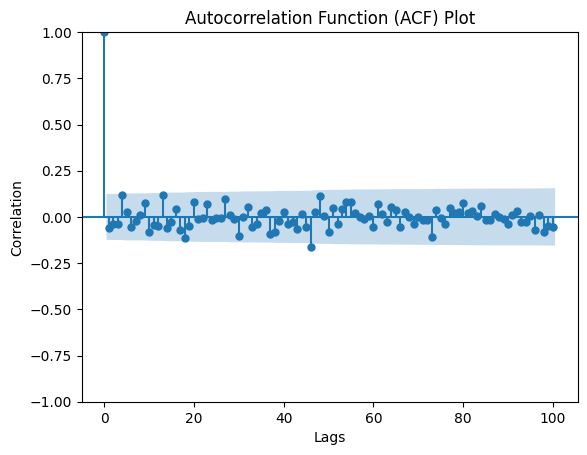

In [10]:
# Looks uncorrelated
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(daily_ic["ic_sign"], lags=100)
plt.title("Autocorrelation Function (ACF) Plot")
plt.xlabel("Lags")
plt.ylabel("Correlation")
plt.show()

In [11]:
agg_absorb_ratio = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  (
                      pl.when(pl.col("side") == "B").then(1)
                      .when(pl.col("side") == "A").then(-1)
                      .when(pl.col("side") == "N").then(0)
                      * pl.col('ref_price') * pl.col("total_imbalance_qty")
                  ).alias("dollar_imbalance"),
                  (
                      pl.col("paired_qty") * pl.col('ref_price')
                  ).alias("paired_dollars")
    )
    .group_by(["date"], maintain_order=True)
    .agg(
        (pl.col("dollar_imbalance").sum() / (pl.col("paired_dollars") + pl.col("dollar_imbalance")).sum()).alias("absorb_ratio")
    )
    .collect(engine="streaming")
)
agg_absorb_ratio

date,absorb_ratio
date,f64
2025-06-11,-0.059206
2025-06-12,0.018834
2025-06-26,-0.071004
2025-11-03,0.014374
2025-11-04,-0.079557
…,…
2025-10-27,0.053104
2025-10-28,-0.044438
2025-10-29,0.022007


In [12]:
ic_data = (
    daily_ic
    .join(agg_absorb_ratio, on="date")
)
ic_data

date,ic_sign,absorb_ratio
date,f64,f64
2025-06-11,0.089116,-0.059206
2025-06-12,0.007078,0.018834
2025-06-26,0.185093,-0.071004
2025-11-03,-0.022613,0.014374
2025-11-04,-0.155311,-0.079557
…,…,…
2025-10-27,-0.202639,0.053104
2025-10-28,-0.038079,-0.044438
2025-10-29,-0.117116,0.022007


In [13]:
import statsmodels.api as sm
X = sm.add_constant(ic_data['absorb_ratio'].to_numpy())
y = ic_data['ic_sign'].to_numpy()

model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     2.220
Date:                Mon, 29 Jun 2026   Prob (F-statistic):              0.138
Time:                        13:59:27   Log-Likelihood:                 148.51
No. Observations:                 248   AIC:                            -293.0
Df Residuals:                     246   BIC:                            -286.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0464      0.009      5.448      0.0

In [14]:
# ======================================================================
# Regime-feature screen: regress daily IC (and |IC|) on day-level features
# Target = continuous daily IC of the raw imbalance signal (daily_ic["ic_sign"]).
# Every feature is ONE value per day, known at 15:50 (no lookahead).
# NOTE: ind_match_price / collars are EXCLUDED -- they only print at 15:55,
#       after the MOC cutoff, so they are unusable at a 15:50 decision.
# ======================================================================
import statsmodels.api as sm

# ---- per-name auction snapshot at 15:50 (first imbalance print >= 15:50) ----
imb_snap = (
    adapter.scan_data(tickers=UNIVERSE, start_date=START, end_date=END,
                      dataset=DATASET, schema="imbalance")
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty",
             "ref_price", "significant_imbalance"])
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"),
                  pl.col("symbol").cast(pl.Categorical))
    .filter(pl.col("symbol").is_in(ACTIVE_SET),
            pl.col("ts_event").dt.time() >= pl.time(15, 50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price",
                 "significant_imbalance"]).first())
    .with_columns(
        pl.when(pl.col("side") == "B").then(1)
        .when(pl.col("side") == "A").then(-1).otherwise(0).alias("sign"),
    )
    .with_columns(
        (pl.col("sign") * pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("signed_imb_dollars"),
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("imb_dollars"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
    )
    .collect(engine="streaming")
)

# ---- A/B: imbalance-book day features ----
day_imb = (
    imb_snap.group_by("date", maintain_order=True)
    .agg(
        pl.col("sign").mean().abs().alias("breadth"),                                              # A: one-sidedness
        (pl.col("signed_imb_dollars").sum() / pl.col("paired_dollars").sum()).alias("net_signed_imb"),   # A: net directional pressure
        (pl.col("imb_dollars").sum() / (pl.col("paired_dollars") + pl.col("imb_dollars")).sum()).alias("absorb_ratio_mag"),  # B: unsigned absorption
        (~pl.col("significant_imbalance").cast(pl.Utf8).is_in(["0", "N", "~", ""])).mean().alias("sig_imb_frac"),  # B: significant-flag prevalence
        pl.col("paired_dollars").sum().alias("tot_paired_dollars"),
    )
)

# ---- C/F: price-action day features (from `data`, mids, known at 15:50) ----
day_px = (
    data.group_by("date", maintain_order=True)
    .agg(
        pl.col("recent_return").abs().mean().alias("mkt_vol"),      # C: realized-vol proxy
        pl.col("recent_return").std().alias("xs_disp"),            # C: cross-sectional dispersion
        pl.col("recent_return").mean().alias("mkt_trend"),         # F: signed market move into the close
        pl.col("spread_return").mean().alias("mean_spread"),       # C: liquidity regime
    )
)

# ---- A: auction participation = closing-auction $ / ADV ----
day_adv = avg_daily_dollar_volume.group_by("date", maintain_order=True).agg(pl.col("ADV").sum().alias("tot_adv"))

# ---- D: calendar / forced-flow dummies (all knowable ex-ante) ----
cal = (
    daily_ic.select("date")
    .with_columns(pl.col("date").dt.truncate("1mo").alias("ym"))
    .with_columns(
        (pl.col("date").dt.weekday() == 5).cast(pl.Int8).alias("is_friday"),
        ((pl.col("date").dt.weekday() == 5) & pl.col("date").dt.day().is_between(15, 21)).cast(pl.Int8).alias("is_opex"),
        ((pl.col("date").dt.weekday() == 5) & pl.col("date").dt.day().is_between(15, 21)
         & pl.col("date").dt.month().is_in([3, 6, 9, 12])).cast(pl.Int8).alias("is_quad_witch"),
        pl.col("date").dt.weekday().alias("dow"),
        (pl.col("date") == pl.col("date").max().over("ym")).cast(pl.Int8).alias("is_month_end"),
    )
    .with_columns(((pl.col("is_month_end") == 1) & pl.col("date").dt.month().is_in([3, 6, 9, 12])).cast(pl.Int8).alias("is_quarter_end"))
    .drop("ym")
)

# ---- assemble one day-level table keyed on date ----
day_features = (
    daily_ic.rename({"ic_sign": "ic"})            # daily_ic["ic_sign"] is the continuous Spearman IC
    .join(day_imb, on="date")
    .join(day_px, on="date")
    .join(day_adv, on="date")
    .join(cal, on="date")
    .sort("date")
    .with_columns(
        (pl.col("tot_paired_dollars") / pl.col("tot_adv")).alias("auction_participation"),  # A
        pl.col("ic").shift(1).alias("ic_lag1"),    # E: persistence (ACF already ~flat)
        pl.col("ic").abs().alias("abs_ic"),
    )
)

# ---- univariate OLS screen: each feature vs continuous IC and |IC| ----
feature_cols = ["breadth", "net_signed_imb", "absorb_ratio_mag", "sig_imb_frac",
                "auction_participation", "mkt_vol", "xs_disp", "mkt_trend", "mean_spread",
                "is_friday", "is_opex", "is_quad_witch", "is_month_end", "is_quarter_end",
                "dow", "ic_lag1"]

pdf = day_features.to_pandas()
rows = []
for tgt in ["ic", "abs_ic"]:
    for f in feature_cols:
        sub = pdf[[tgt, f]].dropna()
        if len(sub) < 30 or sub[f].std() == 0:
            continue
        xz = (sub[f] - sub[f].mean()) / sub[f].std()            # z-score so betas are comparable
        m = sm.OLS(sub[tgt].to_numpy(), sm.add_constant(xz.to_numpy())).fit()
        rows.append({"target": tgt, "feature": f, "beta_per_sd": m.params[1],
                     "t": m.tvalues[1], "p": m.pvalues[1], "r2": m.rsquared, "n": len(sub)})

bonf = 0.05 / len(feature_cols)
results = (
    pl.DataFrame(rows)
    .with_columns((pl.col("p") < bonf).alias("sig_bonferroni"))
    .sort(pl.col("t").abs(), descending=True)
)
print(f"Bonferroni threshold (p < 0.05/{len(feature_cols)}) = {bonf:.4f}\n"
      f"Univariate screen, sorted by |t|.  Treat anything not Bonferroni-significant as noise.\n")
with pl.Config(tbl_rows=60, tbl_width_chars=200):
    print(results)


[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
Bonferroni threshold (p < 0.05/16) = 0.0031
Univariate screen, sorted by |t|.  Treat anything not Bonferroni-significant as noise.

shape: (30, 8)
┌────────┬───────────────────────┬─────────────┬───────────┬──────────┬───────────┬─────┬────────────────┐
│ target ┆ feature               ┆ beta_per_sd ┆ t         ┆ p        ┆ r2        ┆ n   ┆ sig_bonferroni │
│ ---    ┆ ---                   ┆ ---         ┆ ---       ┆ ---      ┆ ---       ┆ --- ┆ ---            │
│ str    ┆ str                   ┆ f64         ┆ f64       ┆ f64      ┆ f64       ┆ i64 ┆ bool           │
╞════════╪═══════════════════════╪═════════════╪═══════════╪══════════╪═══════════╪═════╪════════════════╡
│ ic     ┆ net_signed_imb        ┆ -0.026742   ┆ -3.198846 ┆ 0.001561 ┆ 0.039935  ┆ 248 ┆ true           │
│ abs_ic ┆ mkt_trend             ┆ -0.015109   ┆ -2.796394 ┆ 0.005576 ┆ 0.030809  ┆ 248 ┆ false          │
│ ic     ┆ mkt_trend            

In [15]:
imb_snap['significant_imbalance'].unique()

significant_imbalance
str
"""~"""
